<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Desafío 4: traductor inglés → español con Seq2Seq (versión 2)

**Autor:** Leandro A. Britez

## 1. Introducción y objetivo

**Consigna**

* Replicar el modelo traductor desarrollado en clase y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

El punto de partida es el traductor *encoder-decoder* con LSTM desarrollado en clase (`Traductor.ipynb`). El encoder lee la oración en inglés y la resume en sus estados finales $(h, c)$; el decoder genera la traducción en español palabra por palabra a partir de esos estados. Durante el entrenamiento el decoder recibe como entrada la palabra correcta anterior (*teacher forcing*); en la inferencia recibe la palabra que él mismo predijo en el paso previo (decodificación *greedy*).

Se realizan cuatro experimentos, con configuraciones fijadas antes de entrenar:

| Exp. | Datos | Unidades LSTM | Capas LSTM | Propósito |
|---|---|---|---|---|
| E0 | 10.000 oraciones, largos máximos 20 / 22, vocabulario 8.000 | 256 | 1 | Réplica adaptada del modelo de clase |
| E1 | 60.000 oraciones, sin truncar, vocabulario 12.000 / 15.000 | 256 | 1 | Escenario extendido (E0 vs. E1) |
| E2 | Igual que E1 | 512 | 1 | Más unidades (E1 vs. E2) |
| E3 | Igual que E1 | 256 | 2 | Más capas (E1 vs. E3) |

Cada configuración se entrena una sola vez, por lo que las comparaciones son sin estimar la variabilidad entre ejecuciones.

> **Ejecución:** el notebook está pensado para Google Colab con GPU

## 2. Librerías y carga del dataset

In [1]:
import os
import time
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, text_to_word_sequence
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Aviso de Keras al cargar pesos en un modelo compilado que todavía no entrenó (no afecta los pesos)
warnings.filterwarnings('ignore', message='Skipping variable loading for optimizer')

print(f"TensorFlow {tf.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Parámetros comunes a todos los experimentos. Los de entrenamiento son los del notebook de clase. La semilla fija la mezcla de los datos y la inicialización de los pesos.

In [ ]:
SEED = 40                 # misma semilla que en clase
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 5e-4
EMBED_DIM = 50            # GloVe de 50 dimensiones en el encoder
DEC_EMBED_DIM = 256       # embedding del decoder, igual en todos los experimentos (ver sección 8)

tf.keras.utils.set_random_seed(SEED)

# Pesos e historiales de cada experimento. Para conservarlos entre sesiones de Colab
RESULTS_DIR = 'resultados_v2'
PREV_DIR = 'resultados_desafio4'   # pesos de la primera versión
os.makedirs(RESULTS_DIR, exist_ok=True)

Se descarga el dataset inglés-español utilizado en clase y se mezcla con la misma semilla, de modo que las primeras 10.000 oraciones coinciden con las del notebook original.

In [3]:
if not os.path.exists('spa-eng'):
    os.system("curl -L -o spa-eng.zip http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip")
    os.system("unzip -q spa-eng.zip")

with open("./spa-eng/spa.txt", encoding='utf-8') as f:
    lines = f.read().split("\n")[:-1]

np.random.seed(SEED)
np.random.shuffle(lines)

pairs = [line.rstrip().split('\t')[:2] for line in lines if '\t' in line]
all_en = [p[0] for p in pairs]
all_es = [p[1] for p in pairs]

print(f"Líneas: {len(lines):,} | pares válidos: {len(pairs):,}")
print(all_en[0], '->', all_es[0])

Líneas: 118,964 | pares válidos: 118,964
Somebody stole my car. -> Alguien robó mi auto.


**Criterio de partición.** Después de la mezcla se toman bloques consecutivos de oraciones:

| Uso | Índices | Modelos |
|---|---|---|
| Entrenamiento | 0 – 8.499 | E0 |
| Validación | 8.500 – 9.999 | E0 |
| Entrenamiento | 0 – 47.999 | E1, E2, E3 |
| Validación | 48.000 – 53.999 | E1, E2, E3 |
| Test común | 54.000 – 59.999 | E0, E1, E2, E3 |

E0 conserva la división 85 / 15 de clase. La validación se usa para el *early stopping* y la reducción del learning rate. El test común sólo se usa para la evaluación final y ninguna de sus oraciones interviene en el entrenamiento de ningún modelo. Como la validación de E0 forma parte del entrenamiento de E1-E3, las métricas de validación de E0 no son comparables con las del resto; la comparación entre escenarios se hace sobre el test común.

In [4]:
TEST_START, TEST_END = 54_000, 60_000
test_en = all_en[TEST_START:TEST_END]
test_es = all_es[TEST_START:TEST_END]
print(f"Oraciones de test común: {len(test_en):,}")

Oraciones de test común: 6,000


## 3. Preprocesamiento

Se mantiene el procedimiento de clase: el decoder recibe `<sos> + oración` y debe predecir `oración + <eos>`, cada idioma se tokeniza con un `Tokenizer` de Keras y el padding se aplica al inicio en el encoder y al final en el decoder. Como hay dos escenarios de datos, el procedimiento se escribe una sola vez en `prepare_data`. Respecto de clase hay cuatro ajustes:

1. **Tokenizers ajustados sólo con el conjunto de entrenamiento**, para no usar información de validación ni de test.
2. **`<sos>` y `<eos>` en todas las oraciones al ajustar el tokenizer de salida.** En clase se ajusta con `["<sos>", "<eos>"] + output_sentences`, por lo que `<sos>` aparece una sola vez. Con 10.000 oraciones no tiene efecto, pero con más datos y un vocabulario limitado a las palabras más frecuentes `<sos>` podría quedar afuera.
3. **Se agrega `¡` a los filtros de puntuación**, para ejemplos como `¡hola`.
4. **Truncado al final en el decoder** (`truncating='post'`), para conservar el inicio de la oración y el token `<sos>` si una secuencia supera el largo máximo. En el encoder se mantiene el comportamiento de clase.

Si no se indican largos máximos, se usa el mayor observado en entrenamiento y validación, de modo que no se trunca ninguna de esas oraciones.

In [5]:
# Filtros de clase para el español + '¡'
ES_FILTERS = '!"#$%&()*+,-./:;=¿¡?@[\\]^_`{|}~\t\n'


def prepare_data(n_sentences, n_val, max_vocab_in, max_vocab_out, max_input_len=None, max_out_len=None):
    input_sentences = all_en[:n_sentences]
    output_sentences = all_es[:n_sentences]
    split_idx = n_sentences - n_val
    train_es = output_sentences[:split_idx]

    input_tokenizer = Tokenizer(num_words=max_vocab_in)
    input_tokenizer.fit_on_texts(input_sentences[:split_idx])

    output_tokenizer = Tokenizer(num_words=max_vocab_out, filters=ES_FILTERS)
    output_tokenizer.fit_on_texts([s + ' <eos>' for s in train_es] + ['<sos> ' + s for s in train_es])

    def encode(en, es):
        input_integer_seq = input_tokenizer.texts_to_sequences(en)
        output_input_integer_seq = output_tokenizer.texts_to_sequences(['<sos> ' + s for s in es])
        output_integer_seq = output_tokenizer.texts_to_sequences([s + ' <eos>' for s in es])
        return input_integer_seq, output_input_integer_seq, output_integer_seq

    train = encode(input_sentences[:split_idx], train_es)
    val = encode(input_sentences[split_idx:], output_sentences[split_idx:])
    if max_input_len is None:
        max_input_len = max(len(s) for s in train[0] + val[0])
    if max_out_len is None:
        max_out_len = max(len(s) for s in train[2] + val[2])

    def pad(seqs):
        enc, dec_in, dec_out = seqs
        encoder_input_sequences = pad_sequences(enc, maxlen=max_input_len)
        decoder_input_sequences = pad_sequences(dec_in, maxlen=max_out_len, padding='post', truncating='post')
        decoder_output_sequences = pad_sequences(dec_out, maxlen=max_out_len, padding='post', truncating='post')
        return encoder_input_sequences, decoder_input_sequences, decoder_output_sequences

    word2idx_outputs = output_tokenizer.word_index
    return {
        'input_tokenizer': input_tokenizer, 'output_tokenizer': output_tokenizer,
        'word2idx_inputs': input_tokenizer.word_index, 'word2idx_outputs': word2idx_outputs,
        'idx2word_target': {v: k for k, v in word2idx_outputs.items()},
        'num_words_input': min(max_vocab_in, len(input_tokenizer.word_index) + 1),
        'num_words_output': min(max_vocab_out, len(word2idx_outputs) + 1),
        'max_input_len': max_input_len, 'max_out_len': max_out_len,
        'n_train': split_idx, 'n_val': n_val,
        'train': pad(train), 'val': pad(val),
        'test': pad(encode(test_en, test_es)),     # test común, con el vocabulario de este escenario
    }


def describe(data, name):
    counts = np.array(sorted((c for w, c in data['output_tokenizer'].word_counts.items()
                              if w not in ('<sos>', '<eos>')), reverse=True))
    n_used = data['num_words_output'] - 3          # sin el índice 0, <sos> ni <eos>
    print(f"[{name}] train={data['n_train']:,} | val={data['n_val']:,} | "
          f"max_input_len={data['max_input_len']} | max_out_len={data['max_out_len']}")
    print(f"[{name}] vocabulario EN={len(data['word2idx_inputs']):,} (se usan {data['num_words_input'] - 1:,}) | "
          f"ES={len(data['word2idx_outputs']):,} (se usan {data['num_words_output'] - 1:,})")
    print(f"[{name}] tokens ES de train cubiertos: {counts[:n_used].sum() / counts.sum():.1%} "
          f"(con las 8.000 más frecuentes: {counts[:8000].sum() / counts.sum():.1%})")
    print(f"[{name}] proporción de padding en la salida del decoder: {np.mean(data['train'][2] == 0):.1%}")

**Escenario E0:** 10.000 oraciones, 15 % de validación, vocabulario de 8.000 palabras y largos máximos de 20 y 22, como en clase.

**Escenario extendido (E1-E3):** 54.000 oraciones para entrenamiento y validación (más las 6.000 del test común), vocabulario de 12.000 palabras en inglés y 15.000 en español, y largos máximos tomados de los datos. Los límites de vocabulario son los de la primera versión: cubren todo el vocabulario inglés y la gran mayoría de los tokens españoles del entrenamiento (ver cobertura impresa abajo).

In [6]:
data_e0 = prepare_data(10_000, n_val=1_500, max_vocab_in=8_000, max_vocab_out=8_000,
                       max_input_len=20, max_out_len=22)
data_ext = prepare_data(54_000, n_val=6_000, max_vocab_in=12_000, max_vocab_out=15_000)

describe(data_e0, 'E0')
print()
describe(data_ext, 'E1-E3')

print('\nEjemplo (E0):')
for seq in data_e0['train']:
    print(' ', seq[0])

[E0] train=8,500 | val=1,500 | max_input_len=20 | max_out_len=22
[E0] vocabulario EN=4,630 (se usan 4,630) | ES=7,096 (se usan 7,096)
[E0] tokens ES de train cubiertos: 100.0% (con las 8.000 más frecuentes: 100.0%)
[E0] proporción de padding en la salida del decoder: 67.8%

[E1-E3] train=48,000 | val=6,000 | max_input_len=35 | max_out_len=43
[E1-E3] vocabulario EN=9,785 (se usan 9,785) | ES=17,447 (se usan 14,999)
[E1-E3] tokens ES de train cubiertos: 99.2% (con las 8.000 más frecuentes: 96.4%)
[E1-E3] proporción de padding en la salida del decoder: 83.6%

Ejemplo (E0):
  [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 616 719
  17 100]
  [  2 140 569  23 228   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0]
  [140 569  23 228   1   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0]


## 4. Embeddings preentrenados

Como en clase, el embedding del encoder se inicializa con vectores GloVe de 50 dimensiones y se mantiene congelado. Las palabras sin vector GloVe quedan representadas por un vector nulo. El código de descarga y de armado de la matriz es el de clase, con una diferencia: la matriz tiene `len(word_index) + 1` filas (el índice 0 es el padding).

In [7]:
def _is_valid_pickle(path):
    try:
        with open(path, 'rb') as f:
            head = f.read(20)
        return b'<html' not in head.lower() and b'<!doctype' not in head.lower()
    except Exception:
        return False

_PKL_PATH = 'gloveembedding.pkl'
_FILE_ID  = '1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94'

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(f"curl -L -o {_PKL_PATH} "
                  f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'")
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

Descargando gloveembedding.pkl desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94
From (redirected): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94&confirm=t&uuid=6e039092-314a-4984-9160-74cb12355eb6
To: /content/gloveembedding.pkl
100%|██████████| 525M/525M [00:03<00:00, 148MB/s]

Descarga completada.


In [8]:
def load_glove_embeddings(pkl_path):
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz  = os.path.getsize(pkl_path)
    with open(pkl_path, 'rb') as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array  = np.arange(embeddings.shape[0])
    word2idx   = dict(zip(embeddings['word'], idx_array))
    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]['embedding'] if i != -1 else np.zeros(n_features)


def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove, nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            matrix[i] = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
    return matrix


glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
for name, data in [('E0', data_e0), ('E1-E3', data_ext)]:
    data['embedding_matrix'] = build_embedding_matrix(
        data['word2idx_inputs'], glove_embeddings, glove_word2idx, data['num_words_input'], EMBED_DIM)
    n_null = np.sum(np.sum(data['embedding_matrix'][1:] ** 2, axis=1) == 0)
    print(f"[{name}] palabras sin vector GloVe: {n_null:,} de {data['num_words_input'] - 1:,}")

[E0] palabras sin vector GloVe: 189 de 4,630
[E1-E3] palabras sin vector GloVe: 515 de 9,785


## 5. Definición del encoder y decoder Seq2Seq

**Pérdida y accuracy enmascaradas.** En clase, las salidas del decoder se codifican en *one-hot* y la loss (`categorical_crossentropy`) y la accuracy se calculan sobre todas las posiciones de la secuencia, incluido el padding. Se implementó que ambas métricas se calculan sólo sobre los tokens reales ($y \neq 0$). Los datos de entrenamiento se mezclan en cada época.

In [9]:
def masked_loss(y_true, y_pred):
    # Cross-entropy promedio sólo sobre los tokens reales (y_true != 0)
    y_true = tf.cast(y_true, tf.int32)
    ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, 0), ce.dtype)
    return tf.reduce_sum(ce * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    y_hat = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    hits = tf.cast(tf.equal(y_true, y_hat), tf.float32) * mask
    return tf.reduce_sum(hits) / tf.maximum(tf.reduce_sum(mask), 1.0)


def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(((enc_seqs, dec_in_seqs), dec_out_seqs))
    if shuffle:
        ds = ds.shuffle(len(enc_seqs), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

**Encoder y decoder.** Son las funciones de clase. Los modelos de inferencia también son los de clase. `build_model` arma los tres modelos y compila el de entrenamiento.

In [10]:
def build_encoder(nb_words, embed_dim, embedding_matrix, max_input_len, n_units):

    enc_inputs = Input(shape=(max_input_len,), name='encoder_inputs')

    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=embed_dim,
        weights=[embedding_matrix],
        trainable=False,
        name='encoder_embedding'
    )
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))

    enc_lstm_layer = LSTM(n_units, return_state=True, name='encoder_lstm')
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer


def build_decoder(num_words_output, max_out_len, n_units, encoder_states, dec_embed_dim=DEC_EMBED_DIM):

    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')

    dec_emb_layer = Embedding(
        input_dim=num_words_output,
        output_dim=dec_embed_dim,
        name='decoder_embedding'
    )
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))

    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True,
                          name='decoder_lstm')
    dec_out, _, _  = dec_lstm_layer(dec_emb, initial_state=encoder_states)

    dec_dense_layer = Dense(num_words_output, activation='softmax', name='decoder_dense')
    dec_out         = dec_dense_layer(dec_out)

    return dec_inputs, dec_out, dec_emb_layer, dec_lstm_layer, dec_dense_layer


def build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer):
    # Modelo de encoder que sólo devuelve los estados
    enc_emb = enc_emb_layer(enc_inputs)
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return Model(enc_inputs, [state_h, state_c])


def build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units):
    # Modelo de decoder paso a paso (un token por vez)
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    dec_state_h_in   = Input(shape=(n_units,), name='dec_state_h')
    dec_state_c_in   = Input(shape=(n_units,), name='dec_state_c')

    dec_emb_single = dec_emb_layer(dec_input_single)
    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb_single,
        initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out = dec_dense_layer(dec_out)

    return Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_out, h_out, c_out]
    )


def compile_model(model):
    model.compile(
        loss=masked_loss,
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        metrics=[masked_accuracy]
    )


def build_model(data, n_units):
    enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = build_encoder(
        data['num_words_input'], EMBED_DIM, data['embedding_matrix'], data['max_input_len'], n_units
    )
    dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer = build_decoder(
        data['num_words_output'], data['max_out_len'], n_units, enc_states
    )
    model = Model([enc_inputs, dec_inputs], dec_outputs)
    compile_model(model)
    encoder_model = build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer)
    decoder_model = build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units)
    return model, encoder_model, decoder_model

**Traducción.** `translate_sentence` aplica la misma decodificación *greedy* de clase: el encoder produce los estados, el decoder arranca con `<sos>` y en cada paso elige la palabra más probable y la usa como entrada del paso siguiente, hasta generar `<eos>` o alcanzar `max_out_len`. Se modificó para recibir los modelos como argumentos (hay cuatro), procesar un lote de oraciones a la vez (para evaluar 6.000 oraciones en un tiempo razonable) y tratar los estados como una lista, lo que permite usarla también con el modelo de dos capas.

In [11]:
def translate_sentence(input_seq, encoder_model, decoder_model, data):
    # input_seq: array (n, max_input_len). Devuelve una lista con n traducciones.
    states = encoder_model.predict_on_batch(input_seq)
    n = len(input_seq)
    target_seq = np.full((n, 1), data['word2idx_outputs']['<sos>'])
    eos = data['word2idx_outputs']['<eos>']

    output_idx = np.zeros((n, data['max_out_len']), dtype=int)
    finished = np.zeros(n, dtype=bool)
    for t in range(data['max_out_len']):
        output_tokens, *states = decoder_model.predict_on_batch([target_seq] + states)
        idx = np.argmax(output_tokens[:, 0, :], axis=-1)
        output_idx[:, t] = idx
        finished |= (idx == eos)
        if finished.all():
            break
        target_seq = idx.reshape(-1, 1)

    translations = []
    for row in output_idx:
        words = []
        for idx in row:
            if idx == eos:
                break
            if idx > 0:
                words.append(data['idx2word_target'][idx])
        translations.append(' '.join(words))
    return translations

**Evaluación.** 

- **Con *teacher forcing*** (loss y accuracy enmascaradas): el decoder recibe siempre la palabra correcta anterior. Mide qué tan bien predice el próximo token.
- **Inferencia autoregresiva** (BLEU): el modelo traduce sólo, a partir de sus propias predicciones. BLEU compara las traducciones generadas con los de la referencia y penaliza las traducciones demasiado cortas.

BLEU se calcula para todos los modelos sobre las mismas 6.000 oraciones del test común. Hay una sola traducción de referencia por oración, por lo que una traducción válida que use otras palabras también se penaliza.

**Persistencia y reutilización de pesos.** `run_experiment` guarda los pesos y el historial de cada modelo en `RESULTS_DIR` si el notebook se vuelve a ejecutar y esos archivos existen, los carga en lugar de reentrenar. Si en `PREV_DIR` están los pesos de la primera versión, se intenta reutilizar el modelo equivalente.

El preprocesamiento, las particiones y los parámetros de entrenamiento son los de la primera versión. Si algún control falla, el modelo se entrena desde cero. Las métricas de test y BLEU se calculan siempre en la ejecución actual, las curvas de entrenamiento de un modelo reutilizado son las de su entrenamiento original.

In [12]:
# Referencias del test común para BLEU
test_refs = [text_to_word_sequence(s, filters=ES_FILTERS) for s in test_es]
smoothing = SmoothingFunction().method1

# Modelos equivalentes de la primera versión: nombre, (celda, unidades, capas), escenario
PREV_MODELS = {
    'E0': ('E0_replica_LSTM256', ('lstm', 256, 1), 'E0'),
    'E1': ('E1_ext_LSTM256',     ('lstm', 256, 1), 'ext'),
    'E2': ('E3_ext_LSTM512',     ('lstm', 512, 1), 'ext'),
    'E3': ('E5_ext_LSTM256x2',   ('lstm', 256, 2), 'ext'),
}
# Datos impresos por la primera versión para cada escenario
PREV_DATA = {
    'E0':  dict(n_train=8_500,  vocab_in=4_630, vocab_out=7_096,  max_input_len=20, max_out_len=22),
    'ext': dict(n_train=48_000, vocab_in=9_785, vocab_out=17_447, max_input_len=35, max_out_len=43),
}


def load_previous(name, model, data):
    # Devuelve el historial de la primera versión si sus pesos son compatibles; si no, None
    prev_name, prev_cfg, scenario = PREV_MODELS[name]
    weights_path = f'{PREV_DIR}/{prev_name}.weights.h5'
    info_path = f'{PREV_DIR}/{prev_name}.json'
    if not (os.path.exists(weights_path) and os.path.exists(info_path)):
        return None

    with open(info_path) as f:
        info = json.load(f)
    signature = dict(n_train=data['n_train'], vocab_in=len(data['word2idx_inputs']),
                     vocab_out=len(data['word2idx_outputs']),
                     max_input_len=data['max_input_len'], max_out_len=data['max_out_len'])
    cfg = info['cfg']
    problems = []
    if signature != PREV_DATA[scenario]:
        problems.append('datos o vocabulario')
    if (cfg['cell'], cfg['units'], cfg['layers']) != prev_cfg:
        problems.append('arquitectura')
    if not problems:
        try:
            model.load_weights(weights_path)
            emb = model.get_layer('encoder_embedding').get_weights()[0]
            if not np.allclose(emb, data['embedding_matrix']):
                problems.append('índices del vocabulario inglés')
        except Exception as e:
            problems.append(f'pesos ({e})')
    if problems:
        print(f"[{name}] No se reutiliza {prev_name}: no coinciden {', '.join(problems)}.")
        return None
    return {'history': info['history'], 'train_time': info['train_time'],
            'origen': f'reutilizado de la versión 1 ({prev_name})'}


RESULTS = {}


def run_experiment(name, data, build_fn, description):
    tf.keras.utils.set_random_seed(SEED)
    model, encoder_model, decoder_model = build_fn()
    weights_path = f'{RESULTS_DIR}/{name}.weights.h5'
    info_path = f'{RESULTS_DIR}/{name}.json'

    if os.path.exists(weights_path) and os.path.exists(info_path):
        model.load_weights(weights_path)
        with open(info_path) as f:
            info = json.load(f)
        print(f"[{name}] Se cargan pesos e historial de {RESULTS_DIR} ({info['origen']}).")
    else:
        info = load_previous(name, model, data)
        if info is None:
            # Se reconstruye el modelo por si una carga fallida dejó pesos parciales
            tf.keras.utils.set_random_seed(SEED)
            model, encoder_model, decoder_model = build_fn()
            callbacks = [
                ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
                EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
            ]
            t0 = time.time()
            hist = model.fit(
                make_dataset(*data['train'], shuffle=True),
                validation_data=make_dataset(*data['val']),
                epochs=EPOCHS,
                callbacks=callbacks,
                shuffle=False,      # la mezcla se hace en make_dataset
                verbose=2
            )
            info = {'history': {k: [float(v) for v in vals] for k, vals in hist.history.items()},
                    'train_time': time.time() - t0, 'origen': 'entrenado con la versión 2'}
        model.save_weights(weights_path)
        with open(info_path, 'w') as f:
            json.dump(info, f)

    # Evaluación en el test común
    enc, dec_in, dec_out = data['test']
    test_loss, test_acc = model.evaluate(make_dataset(enc, dec_in, dec_out), verbose=0)
    hyps = []
    for i in range(0, len(enc), 500):
        hyps += translate_sentence(enc[i:i + 500], encoder_model, decoder_model, data)
    bleu = 100 * corpus_bleu([[r] for r in test_refs], [h.split() for h in hyps],
                             smoothing_function=smoothing)

    h = info['history']
    best = int(np.argmin(h['val_loss']))
    summary = {
        'Exp.': name, 'Configuración': description,
        'Parámetros entrenables': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        'Épocas': len(h['loss']), 'Mejor época': best + 1,
        'Tiempo (min)': info['train_time'] / 60,
        'Val loss': h['val_loss'][best], 'Val acc': h['val_masked_accuracy'][best],
        'Test loss': test_loss, 'Test acc': test_acc, 'BLEU': bleu,
        'Origen': info['origen'],
    }
    RESULTS[name] = {'model': model, 'encoder': encoder_model, 'decoder': decoder_model,
                     'history': h, 'hyps': hyps, 'summary': summary}
    print(f"[{name}] {summary['Parámetros entrenables']:,} parámetros entrenables | "
          f"{summary['Épocas']} épocas en {summary['Tiempo (min)']:.1f} min | "
          f"val loss={summary['Val loss']:.3f} | val acc={summary['Val acc']:.3f} | "
          f"test acc={test_acc:.3f} | BLEU={bleu:.2f}")


def plot_history(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name in names:
        h = RESULTS[name]['history']
        epochs = range(1, len(h['loss']) + 1)
        line, = axes[0].plot(epochs, h['val_loss'], label=f'{name} validación')
        axes[0].plot(epochs, h['loss'], ls='--', color=line.get_color(), label=f'{name} entrenamiento')
        axes[1].plot(epochs, h['val_masked_accuracy'], color=line.get_color(), label=f'{name} validación')
        axes[1].plot(epochs, h['masked_accuracy'], ls='--', color=line.get_color(), label=f'{name} entrenamiento')
    axes[0].set_title('Loss enmascarada')
    axes[1].set_title('Accuracy enmascarada')
    for ax in axes:
        ax.set_xlabel('Época')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 6. E0: modelo visto en clase

E0 reproduce la arquitectura de clase sobre las mismas 10.000 oraciones (semilla 40), con la división 85 / 15, largos máximos de 20 y 22 y un vocabulario máximo de 8.000 palabras:

Encoder: embedding GloVe de 50 dimensiones congelado, Dropout 0,3 y una LSTM de 256 unidades.
Decoder: embedding de 256 dimensiones, Dropout 0,3, una LSTM de 256 unidades inicializada con los estados $(h, c)$ del encoder y una capa Dense softmax.
Entrenamiento: Adam (5e-4), batch de 64, hasta 30 épocas, con ReduceLROnPlateau y EarlyStopping.
No es una réplica idéntica. Las diferencias más relevantes son:

- Métricas sin padding: la loss y la accuracy se calculan sólo sobre los tokens reales. En clase incluían el relleno, que en E0 ocupa cerca del 68 % de las posiciones de salida.
- Test común: además de la validación, el modelo se evalúa con BLEU sobre las oraciones 54.000-59.999, que ningún modelo usa para entrenar.
- Tokenizers ajustados sólo con el conjunto de entrenamiento, y con <sos> y <eos> incluidos en todas las oraciones.

Epoch 1/30
133/133 - 13s - 99ms/step - loss: 6.5316 - masked_accuracy: 0.1468 - val_loss: 5.6642 - val_masked_accuracy: 0.1641 - learning_rate: 5.0000e-04
Epoch 2/30
133/133 - 4s - 32ms/step - loss: 5.7965 - masked_accuracy: 0.1649 - val_loss: 5.4755 - val_masked_accuracy: 0.1757 - learning_rate: 5.0000e-04
Epoch 3/30
133/133 - 4s - 33ms/step - loss: 5.5868 - masked_accuracy: 0.1770 - val_loss: 5.3369 - val_masked_accuracy: 0.1844 - learning_rate: 5.0000e-04
Epoch 4/30
133/133 - 4s - 33ms/step - loss: 5.3966 - masked_accuracy: 0.1925 - val_loss: 5.2275 - val_masked_accuracy: 0.1934 - learning_rate: 5.0000e-04
Epoch 5/30
133/133 - 4s - 33ms/step - loss: 5.2158 - masked_accuracy: 0.2105 - val_loss: 5.0977 - val_masked_accuracy: 0.2066 - learning_rate: 5.0000e-04
Epoch 6/30
133/133 - 4s - 33ms/step - loss: 5.0384 - masked_accuracy: 0.2249 - val_loss: 4.9720 - val_masked_accuracy: 0.2144 - learning_rate: 5.0000e-04
Epoch 7/30
133/133 - 4s - 33ms/step - loss: 4.8742 - masked_accuracy: 0.236

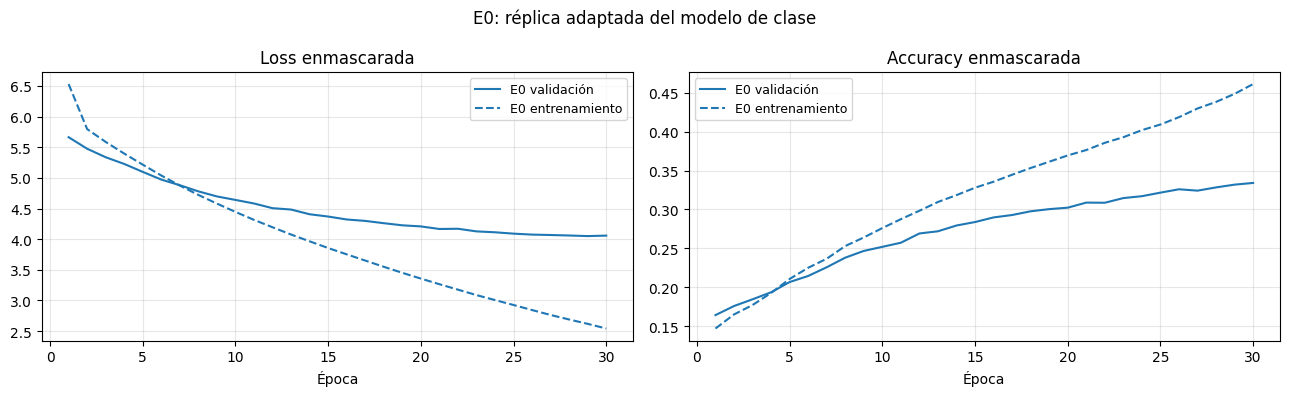

In [13]:
run_experiment('E0', data_e0, lambda: build_model(data_e0, n_units=256), '10k oraciones, LSTM 256 x 1')
plot_history(['E0'], 'E0: réplica adaptada del modelo de clase')

**Observación.**  El modelo usó las 30 épocas sin que actuara el early stopping, y la loss de validación seguía bajando levemente al final. La brecha entre la accuracy de entrenamiento (0,45) y la de validación (0,33) indica que el modelo generaliza poco con 8.500 pares. En el test común alcanza una accuracy de 0,34 con teacher forcing y un BLEU de 3,35: acierta algunas palabras cuando recibe el contexto correcto, pero al traducir solo genera oraciones con muy poca relación con la referencia.

## 7. E1: ampliación del conjunto de entrenamiento

Se mantiene el modelo de E0 (una LSTM de 256 unidades) y se cambia el escenario de datos: 48.000 oraciones de entrenamiento en lugar de 8.500, vocabulario de 12.000 / 15.000 palabras en lugar de 8.000 y largos máximos tomados de los datos en lugar de 20 / 22. Como estos tres factores cambian a la vez, la comparación E0-E1 no permite atribuir una diferencia a uno solo de ellos. Las curvas de E0 y E1 no se superponen porque sus conjuntos de validación son distintos; la comparación se hace con las métricas del test común.

Epoch 1/30
750/750 - 61s - 81ms/step - loss: 5.8741 - masked_accuracy: 0.1746 - val_loss: 5.2331 - val_masked_accuracy: 0.2081 - learning_rate: 5.0000e-04
Epoch 2/30
750/750 - 58s - 78ms/step - loss: 5.0371 - masked_accuracy: 0.2328 - val_loss: 4.7294 - val_masked_accuracy: 0.2555 - learning_rate: 5.0000e-04
Epoch 3/30
750/750 - 59s - 78ms/step - loss: 4.5836 - masked_accuracy: 0.2731 - val_loss: 4.3880 - val_masked_accuracy: 0.2855 - learning_rate: 5.0000e-04
Epoch 4/30
750/750 - 59s - 78ms/step - loss: 4.2398 - masked_accuracy: 0.3030 - val_loss: 4.1301 - val_masked_accuracy: 0.3088 - learning_rate: 5.0000e-04
Epoch 5/30
750/750 - 59s - 78ms/step - loss: 3.9520 - masked_accuracy: 0.3267 - val_loss: 3.9073 - val_masked_accuracy: 0.3322 - learning_rate: 5.0000e-04
Epoch 6/30
750/750 - 59s - 78ms/step - loss: 3.7071 - masked_accuracy: 0.3482 - val_loss: 3.7386 - val_masked_accuracy: 0.3487 - learning_rate: 5.0000e-04
Epoch 7/30
750/750 - 83s - 111ms/step - loss: 3.5016 - masked_accuracy

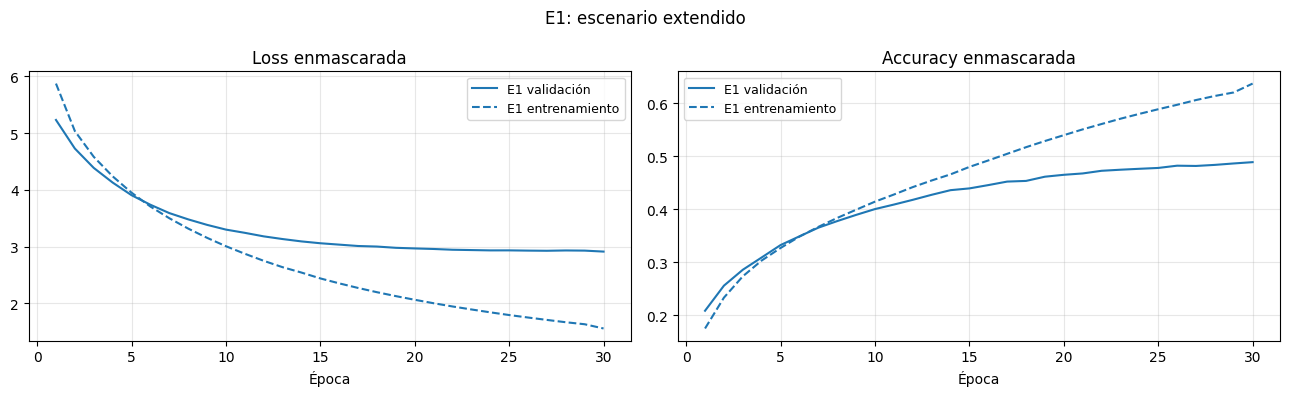

In [14]:
run_experiment('E1', data_ext, lambda: build_model(data_ext, n_units=256), '60k oraciones, LSTM 256 x 1')
plot_history(['E1'], 'E1: escenario extendido')

**Observación.** Con la misma arquitectura y el escenario extendido, la accuracy de test pasa de 0,34 a 0,49 y el BLEU de 3,35 a 11,22, mientras que el tiempo de entrenamiento sube de 2,4 a 30 minutos. La loss de validación casi se aplana desde la época 20, aunque seguía mejorando levemente al final. La mejora es clara, pero no puede atribuirse sólo a la cantidad de datos, porque también cambiaron el vocabulario y la longitud máxima de las secuencias.

## 8. E2: aumento de unidades LSTM

Se duplican las unidades de la LSTM del encoder y del decoder (256 → 512). Los estados $(h, c)$, único canal de información entre encoder y decoder, pasan de 256 a 512 valores. Datos, particiones, embeddings, entrenamiento y evaluación son los de E1. El embedding del decoder se mantiene en 256 dimensiones: en el código de clase su tamaño es `n_units`, por lo que duplicar las unidades también lo habría duplicado y la comparación mezclaría dos cambios.

Epoch 1/30
750/750 - 98s - 131ms/step - loss: 5.6949 - masked_accuracy: 0.1874 - val_loss: 4.9923 - val_masked_accuracy: 0.2299 - learning_rate: 5.0000e-04
Epoch 2/30
750/750 - 96s - 128ms/step - loss: 4.7479 - masked_accuracy: 0.2607 - val_loss: 4.4319 - val_masked_accuracy: 0.2831 - learning_rate: 5.0000e-04
Epoch 3/30
750/750 - 96s - 128ms/step - loss: 4.2302 - masked_accuracy: 0.3028 - val_loss: 4.0408 - val_masked_accuracy: 0.3208 - learning_rate: 5.0000e-04
Epoch 4/30
750/750 - 96s - 128ms/step - loss: 3.8251 - masked_accuracy: 0.3378 - val_loss: 3.7565 - val_masked_accuracy: 0.3474 - learning_rate: 5.0000e-04
Epoch 5/30
750/750 - 96s - 128ms/step - loss: 3.4942 - masked_accuracy: 0.3661 - val_loss: 3.5350 - val_masked_accuracy: 0.3728 - learning_rate: 5.0000e-04
Epoch 6/30
750/750 - 96s - 128ms/step - loss: 3.2184 - masked_accuracy: 0.3911 - val_loss: 3.3711 - val_masked_accuracy: 0.3918 - learning_rate: 5.0000e-04
Epoch 7/30
750/750 - 96s - 128ms/step - loss: 2.9829 - masked_ac

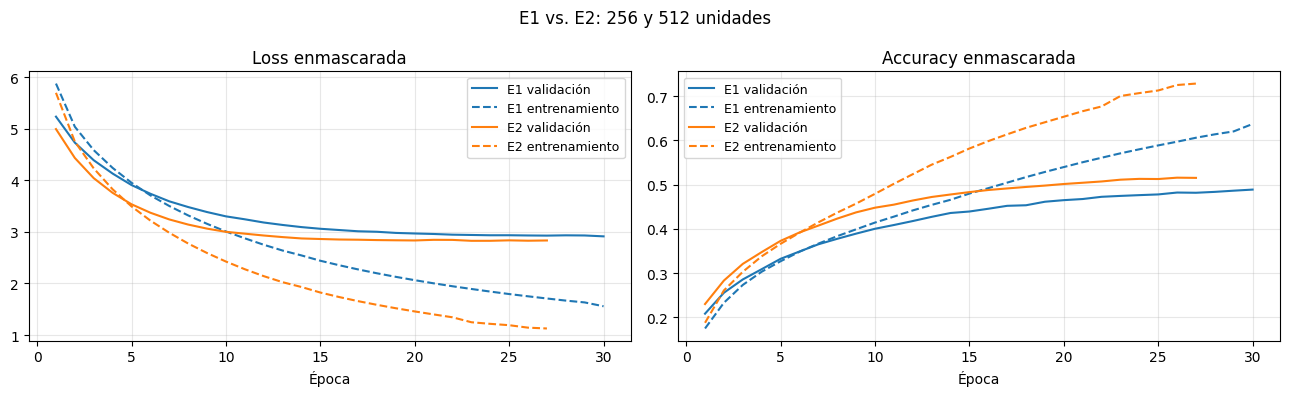

In [15]:
run_experiment('E2', data_ext, lambda: build_model(data_ext, n_units=512), '60k oraciones, LSTM 512 x 1')
plot_history(['E1', 'E2'], 'E1 vs. E2: 256 y 512 unidades')

**Observación.** Con 512 unidades, todas las métricas mejoran respecto de E1: la accuracy de test pasa de 0,494 a 0,516 y el BLEU de 11,22 a 13,67. El modelo converge en menos épocas y muestra una mayor separación entre las curvas de entrenamiento y validación. El mejor resultado de validación se obtuvo en la época 23 y el entrenamiento se detuvo en la 27 mediante early stopping.. El costo es mayor: 14,3 M de parámetros frente a 8,5 M y 43 minutos de entrenamiento frente a 30. Con una sola ejecución no es posible saber qué parte de la mejora se debe a la variabilidad del entrenamiento.

## 9. E3: aumento de capas LSTM

Se apilan dos capas LSTM de 256 unidades en el encoder y dos en el decoder. Datos, embeddings, entrenamiento y evaluación son los de E1.

- **Conexión entre capas.** La primera LSTM del encoder devuelve la secuencia completa de salidas (`return_sequences=True`), que es la entrada de la segunda. La segunda sólo necesita sus estados finales, como la capa única de clase. En el decoder ambas capas devuelven la secuencia completa, porque la `Dense` final predice una palabra en cada posición.
- **Estados.** Cada capa del encoder produce su par $(h, c)$ final. La capa $i$ del decoder se inicializa con los estados de la capa $i$ del encoder, de modo que el decoder recibe dos pares de estados en lugar de uno.
- **Inferencia.** El encoder de inferencia devuelve los cuatro estados $(h_1, c_1, h_2, c_2)$. Como el Dropout no actúa en inferencia, basta con `Model(enc_inputs, enc_states)`, equivalente a volver a aplicar las capas como en clase. El decoder de inferencia recibe la palabra anterior y los cuatro estados, y devuelve la distribución de la siguiente palabra junto con los cuatro estados actualizados. `translate_sentence` no cambia, porque trata los estados como una lista.

No se agrega dropout entre capas ni otro mecanismo, para que la diferencia con E1 sea sólo la segunda capa.

In [16]:
def build_encoder_2l(nb_words, embed_dim, embedding_matrix, max_input_len, n_units):

    enc_inputs = Input(shape=(max_input_len,), name='encoder_inputs')

    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=embed_dim,
        weights=[embedding_matrix],
        trainable=False,
        name='encoder_embedding'
    )
    enc_emb = Dropout(0.3, name='encoder_dropout')(enc_emb_layer(enc_inputs))

    # La primera capa entrega la secuencia completa a la segunda
    enc_lstm_1 = LSTM(n_units, return_sequences=True, return_state=True, name='encoder_lstm_1')
    enc_lstm_2 = LSTM(n_units, return_state=True, name='encoder_lstm_2')
    enc_seq, h1, c1 = enc_lstm_1(enc_emb)
    _, h2, c2 = enc_lstm_2(enc_seq)

    return enc_inputs, [h1, c1, h2, c2]


def build_decoder_2l(num_words_output, max_out_len, n_units, encoder_states, dec_embed_dim=DEC_EMBED_DIM):

    dec_inputs = Input(shape=(max_out_len,), name='decoder_inputs')

    dec_emb_layer = Embedding(
        input_dim=num_words_output,
        output_dim=dec_embed_dim,
        name='decoder_embedding'
    )
    dec_emb = Dropout(0.3, name='decoder_dropout')(dec_emb_layer(dec_inputs))

    # Cada capa del decoder arranca con los estados de la capa equivalente del encoder
    dec_lstm_1 = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm_1')
    dec_lstm_2 = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm_2')
    dec_seq, _, _ = dec_lstm_1(dec_emb, initial_state=encoder_states[:2])
    dec_out, _, _ = dec_lstm_2(dec_seq, initial_state=encoder_states[2:])

    dec_dense_layer = Dense(num_words_output, activation='softmax', name='decoder_dense')
    dec_out         = dec_dense_layer(dec_out)

    return dec_inputs, dec_out, dec_emb_layer, [dec_lstm_1, dec_lstm_2], dec_dense_layer


def build_decoder_inference_2l(dec_emb_layer, dec_lstm_layers, dec_dense_layer, n_units):
    dec_input_single = Input(shape=(1,), name='dec_input_single')
    state_inputs = [Input(shape=(n_units,), name=f'dec_state_{s}') for s in ('h1', 'c1', 'h2', 'c2')]

    dec_emb_single = dec_emb_layer(dec_input_single)
    dec_seq, h1, c1 = dec_lstm_layers[0](dec_emb_single, initial_state=state_inputs[:2])
    dec_out, h2, c2 = dec_lstm_layers[1](dec_seq, initial_state=state_inputs[2:])
    dec_out = dec_dense_layer(dec_out)

    return Model([dec_input_single] + state_inputs, [dec_out, h1, c1, h2, c2])


def build_model_2l(data, n_units):
    enc_inputs, enc_states = build_encoder_2l(
        data['num_words_input'], EMBED_DIM, data['embedding_matrix'], data['max_input_len'], n_units
    )
    dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layers, dec_dense_layer = build_decoder_2l(
        data['num_words_output'], data['max_out_len'], n_units, enc_states
    )
    model = Model([enc_inputs, dec_inputs], dec_outputs)
    compile_model(model)
    encoder_model = Model(enc_inputs, enc_states)
    decoder_model = build_decoder_inference_2l(dec_emb_layer, dec_lstm_layers, dec_dense_layer, n_units)
    return model, encoder_model, decoder_model

Epoch 1/30
750/750 - 68s - 91ms/step - loss: 6.0202 - masked_accuracy: 0.1660 - val_loss: 5.3611 - val_masked_accuracy: 0.1959 - learning_rate: 5.0000e-04
Epoch 2/30
750/750 - 65s - 86ms/step - loss: 5.1629 - masked_accuracy: 0.2238 - val_loss: 4.8543 - val_masked_accuracy: 0.2473 - learning_rate: 5.0000e-04
Epoch 3/30
750/750 - 65s - 86ms/step - loss: 4.7050 - masked_accuracy: 0.2636 - val_loss: 4.5093 - val_masked_accuracy: 0.2748 - learning_rate: 5.0000e-04
Epoch 4/30
750/750 - 65s - 86ms/step - loss: 4.3755 - masked_accuracy: 0.2924 - val_loss: 4.2537 - val_masked_accuracy: 0.3002 - learning_rate: 5.0000e-04
Epoch 5/30
750/750 - 65s - 86ms/step - loss: 4.0949 - masked_accuracy: 0.3193 - val_loss: 4.0298 - val_masked_accuracy: 0.3233 - learning_rate: 5.0000e-04
Epoch 6/30
750/750 - 65s - 86ms/step - loss: 3.8517 - masked_accuracy: 0.3420 - val_loss: 3.8488 - val_masked_accuracy: 0.3453 - learning_rate: 5.0000e-04
Epoch 7/30
750/750 - 65s - 86ms/step - loss: 3.6357 - masked_accuracy:

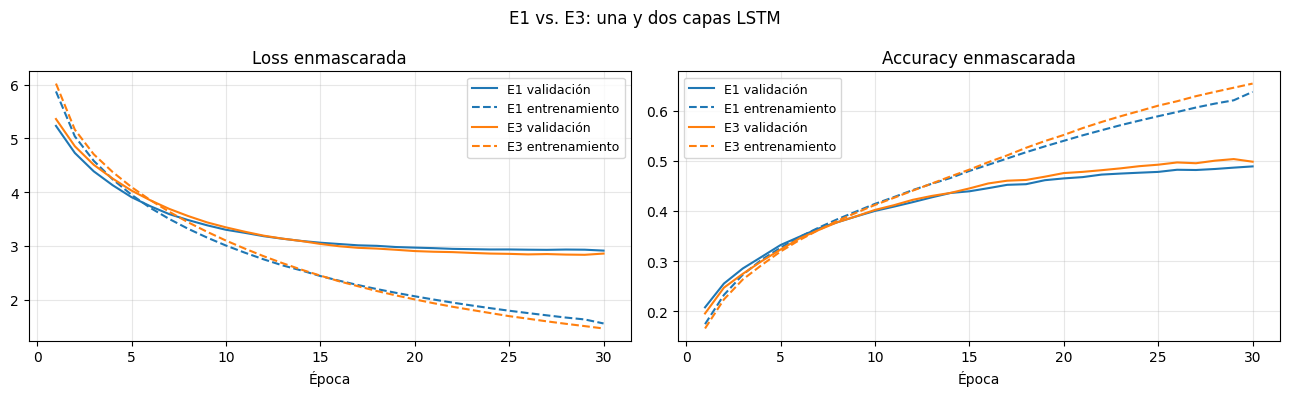

In [17]:
run_experiment('E3', data_ext, lambda: build_model_2l(data_ext, n_units=256), '60k oraciones, LSTM 256 x 2')
plot_history(['E1', 'E3'], 'E1 vs. E3: una y dos capas LSTM')

**Observación.** Con una segunda capa LSTM, las métricas también mejoran respecto de E1: la accuracy de test pasa de 0,494 a 0,507 y el BLEU de 11,22 a 13,45. La capa adicional suma alrededor de 1 M de parámetros, y el modelo seguía mejorando levemente al llegar a las 30 épocas. Frente a E2, el BLEU es muy similar (13,45 frente a 13,67) con menos parámetros. Esa diferencia, en una única ejecución, no alcanza para decidir si conviene aumentar las capas o las unidades.

## 10. Comparación general de resultados


- Val loss / Val acc: corresponden a la mejor época y se miden con teacher forcing. Sólo son comparables entre E1, E2 y E3, porque E0 usa otro conjunto de validación.
- Test loss / Test acc: se miden con teacher forcing sobre el test común. Entre E0 y el resto son orientativas, porque cada escenario usa su propio vocabulario.
- BLEU: se calcula sobre las traducciones generadas, con las mismas referencias para los cuatro modelos. Es la métrica más cercana al uso real del traductor.
- Tiempo (min): depende de la GPU asignada y sirve sólo como referencia.

In [18]:
df_results = pd.DataFrame([r['summary'] for r in RESULTS.values()]).set_index('Exp.')
with pd.option_context('display.max_colwidth', None):
    display(df_results.round({'Tiempo (min)': 1, 'Val loss': 3, 'Val acc': 3,
                              'Test loss': 3, 'Test acc': 3, 'BLEU': 2}))

,Configuración,Parámetros entrenables,Épocas,Mejor época,Tiempo (min),Val loss,Val acc,Test loss,Test acc,BLEU,Origen
Exp.,,,,,,,,,,,
E0,"10k oraciones, LSTM 256 x 1",4480441,30,29,2.4,4.050,0.332,4.030,0.336,3.35,entrenado con la versión 2
E1,"60k oraciones, LSTM 256 x 1",8534680,30,30,30.2,2.913,0.489,2.888,0.494,11.22,entrenado con la versión 2
E2,"60k oraciones, LSTM 512 x 1",14262936,27,23,43.3,2.827,0.511,2.812,0.516,13.67,entrenado con la versión 2
E3,"60k oraciones, LSTM 256 x 2",9585304,30,29,32.5,2.835,0.503,2.822,0.507,13.45,entrenado con la versión 2


**Observación.** En el escenario extendido, las tres métricas comparables ordenan los modelos de la misma forma: E2 y E3 quedan muy cerca entre sí y por encima de E1. La mayor diferencia aparece entre E0 y E1 (unos 8 puntos de BLEU), aunque combina varios cambios a la vez. Con teacher forcing, los modelos extendidos aciertan alrededor de la mitad de los tokens, pero al traducir solos el BLEU no supera 14. Una posible explicación es que, al generar, cada error pasa al paso siguiente y se acumula.

## 11. Ejemplos de traducción

Se muestran siete oraciones del test común: dos cortas (hasta 5 palabras en la referencia), tres intermedias (6 a 10) y dos más largas (11 o más). Se eligen al azar dentro de cada rango, con semilla fija y sin mirar las traducciones, para no seleccionar sólo los casos favorables. Las traducciones generadas aparecen en minúsculas y sin signos de puntuación, porque así las produce el tokenizer.

In [19]:
ref_len = np.array([len(r) for r in test_refs])
rng = np.random.default_rng(SEED)
example_idx = np.concatenate([
    rng.choice(np.where(ref_len <= 5)[0], 2, replace=False),
    rng.choice(np.where((ref_len >= 6) & (ref_len <= 10))[0], 3, replace=False),
    rng.choice(np.where(ref_len >= 11)[0], 2, replace=False),
])

rows = []
for i in example_idx:
    row = {'Inglés': test_en[i], 'Referencia': test_es[i]}
    for name in RESULTS:
        row[name] = RESULTS[name]['hyps'][i]
    rows.append(row)

with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(rows))

,Inglés,Referencia,E0,E1,E2,E3
0,Do you want to kill me?,¿Quieres matarme?,quieres que te quede,quieres que me beses,querés que continue,querés que me
1,Tom escaped injury.,Tom evitó males mayores.,tom se suicidó,tom murió,tom se ha detenido,tom murió de asesinato
2,The pilgrims brought gifts from distant lands.,Los peregrinos trajeron regalos de tierras remotas.,la policía se está cerrando,la casa se ayudaron a los,el nuevo vestido es de felicidad,la tienda se venden a muchos
3,Tom is a member of a secret society.,Tom pertenece a una sociedad secreta.,tom es un gran estrella de bolsillo de la mesa,tom es un gran músico íntima de maría,tom es un amigo de la sociedad moderna,tom es un experto en un grupo de negocios
4,I think about him all the time.,Pienso en él todo el tiempo.,creo que lo que te vayas,creo que todo lo que pasa,me gusta pensar en él,creo que todo el tiempo
5,"Apparently, the murder happened in a locked room.","Aparentemente, el asesinato se perpetró en una habitación cerrada con llave.",en la policía se quedó un accidente de la mesa,ha descubierto la policía que había muerto en el auto,ayer fue un ladrón en la puerta ayer,en el accidente de policía murió de una parada de tránsito
6,"After I graduated from college, I spent two years traveling around the world.","Después de graduarme de la universidad, yo pasé dos años viajando alrededor del mundo.",después de la última vez que había estado en la estación de la ciudad,ayer pasé a las seis años que empecé a estudiar chino,después de graduarme de la escuela los días a las siete de los tres años,después de los dos años se crió en el año pasado


##  12. Conclusiones

Se replicó el traductor de clase y se lo extendió con más datos, más unidades y más capas. El cambio al escenario extendido fue el que más mejoró los resultados (BLEU de 3,35 a 11,22), aunque no puede atribuirse sólo a la cantidad de datos. Sobre ese escenario, tanto E2 como E3 mejoraron respecto de E1 y obtuvieron resultados similares. E3 alcanzó un BLEU apenas inferior al de E2, pero con una cantidad considerablemente menor de parámetros. Con una sola ejecución por modelo, esa diferencia no alcanza para elegir entre más unidades o más capas.

Los ejemplos coinciden con las métricas. En los siete ejemplos seleccionados, ningún modelo logra una traducción completamente satisfactoria, aunque los modelos extendidos recuperan algunos elementos de la oración original (por ejemplo, "me gusta pensar en él" para I think about him all the time). Mientras que E0 casi siempre genera oraciones sin relación con la entrada. Los errores son fluidos y a veces invierten el sentido (Tom escaped injury → "tom murió"). En las oraciones largas, los modelos empiezan bien y luego se pierden. Además, BLEU penaliza variantes válidas como "querés" frente a "quieres", porque hay una sola referencia por oración.

Estas fallas reflejan límites de los modelos. El encoder resume la información de la oración en estados finales de tamaño fijo, la decodificación greedy no puede corregir decisiones previas y el vocabulario por palabras no cubre términos poco frecuentes.